In [1]:
import pandas as pd
import numpy as np

# Display settings — professional readability
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Reproducibility
RANDOM_STATE = 42

In [15]:
import os

print(os.listdir("data"))

['raw']


In [16]:
print(os.listdir("data/raw"))

['european_household_energy.csv']


In [17]:
DATA_PATH = "data/raw/european_household_energy.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,country_code,country_iso2,country,is_country_group,end_use_code,end_use,fuel_code,fuel,period,date,year,energy_tj,flag,flag_meaning
0,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2010,2010-01-01,2010,"10,790.82",NaN,NaN
1,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2011,2011-01-01,2011,"10,571.88",NaN,NaN
2,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2012,2012-01-01,2012,"11,036.88",NaN,NaN
3,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2013,2013-01-01,2013,"14,641.09",NaN,NaN
4,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2014,2014-01-01,2014,"12,600.00",NaN,NaN


In [18]:
df.shape


(33874, 14)

In [20]:
pd.Series(df.columns, name="column_name")

0         country_code
1         country_iso2
2              country
3     is_country_group
4         end_use_code
5              end_use
6            fuel_code
7                 fuel
8               period
9                 date
10                year
11           energy_tj
12                flag
13        flag_meaning
Name: column_name, dtype: str

In [21]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 33874 entries, 0 to 33873
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   country_code      33874 non-null  str    
 1   country_iso2      33356 non-null  str    
 2   country           33874 non-null  str    
 3   is_country_group  33874 non-null  bool   
 4   end_use_code      33874 non-null  str    
 5   end_use           33874 non-null  str    
 6   fuel_code         33874 non-null  str    
 7   fuel              33874 non-null  str    
 8   period            33874 non-null  int64  
 9   date              33874 non-null  str    
 10  year              33874 non-null  int64  
 11  energy_tj         33874 non-null  float64
 12  flag              71 non-null     str    
 13  flag_meaning      71 non-null     str    
dtypes: bool(1), float64(1), int64(2), str(10)
memory usage: 7.7 MB


In [22]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
period,"33,874.00","2,018.07",3.99,"2,010.00","2,015.00","2,018.00","2,021.00","2,024.00"
year,"33,874.00","2,018.07",3.99,"2,010.00","2,015.00","2,018.00","2,021.00","2,024.00"
energy_tj,"33,874.00","31,986.54","227,443.58",0.00,0.00,149.75,"5,948.24","10,975,898.71"


In [23]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2),
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0]
missing_summary.sort_values("missing_pct", ascending=False)

,missing_count,missing_pct
flag,33803,99.79
flag_meaning,33803,99.79
country_iso2,518,1.53


In [24]:
duplicates_count = df.duplicated().sum()
duplicates_count

np.int64(0)

In [25]:
key_cols = ["country", "year", "end_use_code", "fuel_code"]
key_duplicates = df.duplicated(subset=key_cols).sum()
key_duplicates

np.int64(0)

In [26]:
data_dictionary = pd.DataFrame({
    "column": df.columns,
    "description": [
        "ISO-2 country code (e.g., AL, DE)",
        "ISO-2 code repeated (legacy field)",
        "Country name in English",
        "True if the row aggregates multiple countries (e.g., EU27)",
        "Code of end-use category (e.g., FC_OTH_HH_E = total household energy use)",
        "Human-readable end-use label",
        "Fuel/source code (e.g., E7000 = Electricity, TOTAL = all fuels)",
        "Human-readable fuel label",
        "Reporting period as string",
        "Period as datetime",
        "Year as integer",
        "Energy consumption in Terajoules (TJ) — the main measure",
        "Data quality flag code",
        "Meaning of the flag",
    ],
})

data_dictionary

,column,description
0,country_code,"ISO-2 country code (e.g., AL, DE)"
1,country_iso2,ISO-2 code repeated (legacy field)
2,country,Country name in English
3,is_country_group,True if the row aggregates multiple countries ...
4,end_use_code,"Code of end-use category (e.g., FC_OTH_HH_E = ..."
5,end_use,Human-readable end-use label
6,fuel_code,"Fuel/source code (e.g., E7000 = Electricity, T..."
7,fuel,Human-readable fuel label
8,period,Reporting period as string
9,date,Period as datetime


In [28]:
(df['country_code'] != df['country_iso2']).sum()

np.int64(2072)

In [30]:
df.groupby(
    ['country', 'is_country_group']
).size().reset_index(name='records')

,country,is_country_group,records
0,Albania,False,1110
1,Austria,False,1110
2,Belgium,False,666
3,Bosnia and Herzegovina,False,814
4,Bulgaria,False,1110
5,Croatia,False,1110
6,Cyprus,False,518
7,Czechia,False,740
8,Denmark,False,740
9,Estonia,False,1110


In [31]:
df['end_use'].value_counts()

end_use
Final consumption - other sectors - households - energy use                                         6419
Final consumption - other sectors - households - energy use - water heating                         6419
Final consumption - other sectors - households - energy use - space heating                         6415
Final consumption - other sectors - households - energy use - cooking                               6409
Final consumption - other sectors - households - energy use - other end use                         6368
Final consumption - other sectors - households - energy use - lighting and electrical appliances     922
Final consumption - other sectors - households - energy use - space cooling                          922
Name: count, dtype: int64

In [32]:
df['fuel'].value_counts()

fuel
Total                                                               3224
Electricity                                                         3220
Oil and petroleum products                                          2302
Renewables and biofuels                                             2302
Natural gas                                                         2298
Primary solid biofuels                                              2298
Solid fossil fuels, peat, peat products, oil shale and oil sands    2295
Liquefied petroleum gases                                           2294
Heat                                                                2291
Other kerosene                                                      2270
Gas oil and diesel oil                                              2270
Biogases                                                            2270
Solar thermal                                                       2270
Ambient heat (heat pumps)                     

In [33]:
df[['flag', 'flag_meaning']].drop_duplicates()

,flag,flag_meaning
0,NaN,NaN
12039,u,low reliability
23362,e,estimated


In [34]:
df[['period', 'year']].drop_duplicates().sort_values('year')

,period,year
0,2010,2010
1,2011,2011
2,2012,2012
3,2013,2013
4,2014,2014
5,2015,2015
6,2016,2016
7,2017,2017
8,2018,2018
9,2019,2019


In [36]:
countries_overview = (
    df
    .groupby(["is_country_group"])
    .agg(
        rows=("country", "size"),
        unique_countries=("country", "nunique"),
    )
)

countries_overview

,rows,unique_countries
is_country_group,,
False,33356,39
True,518,1


In [40]:
fuel_overview = (
    df[["fuel_code", "fuel"]]
    .drop_duplicates()
    .sort_values("fuel_code")
    .reset_index(drop=True)
)

fuel_overview

,fuel_code,fuel
0,E7000,Electricity
1,G3000,Natural gas
2,H8000,Heat
3,O4000,Oil and petroleum products
4,O4630,Liquefied petroleum gases
5,O4669,Other kerosene
6,O4671,Gas oil and diesel oil
7,R5110-5150_W6000RI,Primary solid biofuels
8,R5300,Biogases
9,RA000,Renewables and biofuels


In [43]:
energy_checks = pd.DataFrame({
    "metric": [
        "negative_values",
        "zero_values",
        "positive_values",
        "total_rows",
        "min_positive_value",
        "max_value",
    ],
    "value": [
        (df["energy_tj"] < 0).sum(),
        (df["energy_tj"] == 0).sum(),
        (df["energy_tj"] > 0).sum(),
        len(df),
        df.loc[df["energy_tj"] > 0, "energy_tj"].min(),
        df["energy_tj"].max(),
    ],
})

energy_checks

,metric,value
0,negative_values,0.00
1,zero_values,"14,742.00"
2,positive_values,"19,132.00"
3,total_rows,"33,874.00"
4,min_positive_value,0.00
5,max_value,"10,975,898.71"


## 📋 Data Understanding Report — Phase 1

### 1. Dataset Purpose
The dataset reports **final energy consumption in European households**, broken down by:
- Country
- Year (2010–2024)
- End-use (space heating, cooking, lighting, etc.)
- Fuel type (electricity, gas, oil, renewables, etc.)

### 2. Dataset Size
- Rows: *(see Cell 4 output)*
- Columns: 15

### 3. Column Roles
| Role | Columns |
|---|---|
| **Identifiers** | country_code, country_iso2, country, is_country_group |
| **Category codes** | end_use_code, end_use, fuel_code, fuel |
| **Time** | period, date, year |
| **Measure** | energy_tj |
| **Quality metadata** | flag, flag_meaning |

### 4. Data Types
- **Numerical:** `year`, `energy_tj`
- **Categorical:** all remaining `object` columns + `is_country_group` (bool)
- **Temporal:** `date` (currently `object` → needs conversion in Phase 2)

### 5. Key Structural Observations
1. The dataset mixes **individual countries** and **country groups** (`is_country_group`).
   → Must filter to real countries in any country-level analysis.
2. Both **aggregated fuels** (e.g., `RA000` Renewables, `O4000` Oil products) and **sub-fuels** exist.
   → Risk of double counting; must define which level to use per question.
3. `energy_tj` is **right-skewed** with a wide range (from near-zero to very large values).
   → Log scale may be needed in visualizations.
4. Missing values are concentrated in `flag` and `flag_meaning` — **not in the measure itself**.
5. No fully duplicated rows; a formal check on the analytical key will be finalized in Phase 2.

### 6. Initial Data Quality Concerns (to resolve in Phase 2)
- Zero values → valid zeros vs. unreported data.
- Data type of `date` → convert to `datetime`.
- Coverage of years **per country** → not all countries may have all 15 years.
- Consistency between `TOTAL` row and sum of individual fuels/end-uses.
- Country code/name consistency across the file.

### 7. Initial Hypotheses for Phase 3 (EDA)
- Electricity and natural gas dominate household energy across Europe.
- Space heating is the largest end-use overall.
- Renewable share grows over time but unevenly across countries.
- COVID-19 (2020–2021) may show a visible spike in household consumption.

---
**Status:** Phase 1 complete. Ready for Phase 2 — Data Cleaning.

In [44]:
cleaning_log = []

def log_step(step: int, action: str, reason: str, rows_affected):
    cleaning_log.append({
        "step": step,
        "action": action,
        "reason": reason,
        "rows_affected": rows_affected,
    })

log_step(0, "Initial load", "Raw CSV loaded without modification", len(df))
len(cleaning_log)

1

In [45]:
string_cols = df.select_dtypes(include="object").columns.tolist()

for col in string_cols:
    df[col] = df[col].astype(str).str.strip()

# Empty strings -> NaN (so they are treated as missing, not as a category)
df[string_cols] = df[string_cols].replace({"": np.nan, "nan": np.nan})

log_step(1, "Strip whitespace + empty strings -> NaN",
         "Prevent hidden duplicates from trailing/leading spaces", len(df))

df[string_cols].nunique().sort_values(ascending=False).to_frame(name="n_unique")

C:\Users\LOQ\AppData\Local\Temp\ipykernel_37092\1641110779.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_cols = df.select_dtypes(include="object").columns.tolist()


,n_unique
country_code,40
country,40
country_iso2,39
date,15
fuel,14
fuel_code,14
end_use,7
end_use_code,7
flag,2
flag_meaning,2


In [46]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Consistency check: year column must match date year
year_mismatch = (df["date"].dt.year != df["year"]).sum()

log_step(2, "Convert date to datetime",
         "Enable time-series operations; verify date-year consistency",
         len(df))

pd.DataFrame({
    "check": ["date dtype", "null dates after conversion", "year vs date.year mismatches"],
    "value": [str(df["date"].dtype), df["date"].isna().sum(), year_mismatch],
})

,check,value
0,date dtype,datetime64[us]
1,null dates after conversion,0
2,year vs date.year mismatches,0


In [47]:

key_cols = ["country", "year", "end_use_code", "fuel_code"]

key_dups = df[df.duplicated(subset=key_cols, keep=False)].sort_values(key_cols)

duplicate_report = pd.DataFrame({
    "check": ["full row duplicates", "key duplicates (all occurrences)"],
    "count": [df.duplicated().sum(), len(key_dups)],
})

duplicate_report

,check,count
0,full row duplicates,0
1,key duplicates (all occurrences),0


In [48]:
conflicting = (
    key_dups
    .groupby(key_cols)["energy_tj"]
    .nunique()
    .reset_index(name="n_distinct_values")
    .query("n_distinct_values > 1")
)

conflicting.head(20)

,country,year,end_use_code,fuel_code,n_distinct_values


In [49]:
before = len(df)
df = df.drop_duplicates()
removed = before - len(df)

log_step(3, "Drop exact duplicate rows",
         "Exact duplicates carry no information", removed)

pd.DataFrame({"rows_before": [before], "rows_after": [len(df)], "removed": [removed]})

,rows_before,rows_after,removed
0,33874,33874,0


In [50]:
groups_df = df[df["is_country_group"] == True].copy()
countries_df = df[df["is_country_group"] == False].copy()

country_groups_list = sorted(groups_df["country"].dropna().unique().tolist())

log_step(4, "Separate country groups from real countries",
         "Prevent double counting in country-level analysis",
         len(groups_df))

pd.DataFrame({
    "dataset": ["Real countries", "Country groups"],
    "rows": [len(countries_df), len(groups_df)],
    "unique_entities": [countries_df["country"].nunique(), groups_df["country"].nunique()],
})

,dataset,rows,unique_entities
0,Real countries,33356,39
1,Country groups,518,1


In [51]:
pd.Series(country_groups_list, name="country_group")

0    European Union - 27 countries (from 2020)
Name: country_group, dtype: str

In [52]:
fuel_hierarchy = pd.DataFrame({
    "fuel_code": [
        "TOTAL",
        "RA000", "O4000", "SFF_P1000_S2000", "G3000", "E7000", "H8000",
        "O4630", "O4669", "O4671",
        "R5110-5150_W6000RI", "R5300", "RA410", "RA600",
    ],
    "fuel_label": [
        "TOTAL",
        "Renewables & biofuels", "Oil & petroleum products",
        "Solid fossil fuels", "Natural gas", "Electricity", "Heat",
        "Liquefied petroleum gases", "Other kerosene", "Gas/diesel oil",
        "Primary solid biofuels", "Biogases", "Solar thermal",
        "Ambient heat (heat pumps)",
    ],
    "level": [
        "grand_total",
        "aggregate", "aggregate", "aggregate", "primary", "primary", "primary",
        "sub_fuel", "sub_fuel", "sub_fuel",
        "sub_fuel", "sub_fuel", "sub_fuel", "sub_fuel",
    ],
})

df = df.merge(fuel_hierarchy, on="fuel_code", how="left")

log_step(5, "Tag fuel rows as aggregate / primary / sub_fuel",
         "Avoid double counting when summing fuels",
         len(df))

df["level"].value_counts(dropna=False).to_frame(name="rows")

,rows
level,
sub_fuel,15942
primary,7809
aggregate,6899
grand_total,3224


In [53]:
unmapped_fuels = (
    df.loc[df["level"].isna(), ["fuel_code", "fuel"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
unmapped_fuels

,fuel_code,fuel


In [54]:

df["is_zero"] = df["energy_tj"] == 0

fuel_country_has_positive = (
    df[df["energy_tj"] > 0]
    .groupby(["country", "fuel_code"])["energy_tj"]
    .max()
    .rename("max_positive")
    .reset_index()
)

df = df.merge(fuel_country_has_positive, on=["country", "fuel_code"], how="left")
df["zero_type"] = np.where(
    ~df["is_zero"], "not_zero",
    np.where(df["max_positive"].isna(), "all_zero_series", "valid_zero")
)

zero_summary = df.groupby("zero_type")["energy_tj"].size().to_frame(name="rows")
zero_summary["pct"] = (zero_summary["rows"] / len(df) * 100).round(2)

log_step(6, "Classify zero values (valid_zero vs all_zero_series)",
         "Distinguish real zeros from potential non-reporting",
         int(df["is_zero"].sum()))

zero_summary


,rows,pct
zero_type,,
all_zero_series,6135,18.11
not_zero,19132,56.48
valid_zero,8607,25.41


In [55]:
coverage = (
    countries_df
    .groupby("country")["year"]
    .agg(["min", "max", "nunique"])
    .rename(columns={"min": "first_year", "max": "last_year", "nunique": "n_years"})
    .sort_values("n_years")
)

coverage["missing_years"] = (df["year"].nunique()) - coverage["n_years"]

log_step(7, "Check year coverage per country",
         "Detect incomplete time series before trend analysis",
         int((coverage["missing_years"] > 0).sum()))

coverage

,first_year,last_year,n_years,missing_years
country,,,,
Turkiye,2022,2024,3,12
Ukraine,2016,2020,5,10
Cyprus,2018,2024,7,8
Moldova,2017,2024,8,7
Lithuania,2017,2024,8,7
Kosovo*,2017,2024,8,7
Georgia,2016,2024,9,6
Belgium,2016,2024,9,6
Romania,2015,2024,10,5


In [56]:
base = countries_df[countries_df["end_use_code"] == "FC_OTH_HH_E"].copy()
base = base.merge(fuel_hierarchy, on="fuel_code", how="left")

total_rows = (
    base[base["fuel_code"] == "TOTAL"]
    .groupby(["country", "year"])["energy_tj"]
    .sum()
    .rename("total_reported")
)

primary_sum = (
    base[base["level"].isin(["primary", "sub_fuel"])]
    .groupby(["country", "year"])["energy_tj"]
    .sum()
    .rename("primary_sum")
)

consistency = pd.concat([total_rows, primary_sum], axis=1).dropna()
consistency["diff"] = consistency["total_reported"] - consistency["primary_sum"]
consistency["diff_pct"] = (consistency["diff"] / consistency["total_reported"] * 100).round(2)

log_step(8, "Compare TOTAL vs. sum of primary fuels",
         "Detect reporting inconsistencies between aggregation levels",
         int(consistency["diff_pct"].abs().gt(5).sum()))

consistency.reindex(consistency["diff_pct"].abs().sort_values(ascending=False).index).head(15)

total_reported  primary_sum       diff  diff_pct
country year                                                  
Poland  2015      827,568.21   536,114.81 291,453.40     35.22
        2016      831,936.35   556,168.65 275,767.70     33.15
        2017      840,003.39   564,882.03 275,121.36     32.75
Denmark 2017      191,554.34   131,618.35  59,935.99     31.29
        2016      192,888.48   133,422.47  59,466.00     30.83
        2015      185,988.83   129,509.81  56,479.02     30.37
Poland  2018      944,438.96   686,022.63 258,416.33     27.36
        2020      883,468.32   664,947.01 218,521.31     24.73
        2019      878,969.57   669,732.93 209,236.64     23.80
        2021      926,573.44   722,311.67 204,261.77     22.04
        2023      833,859.50   661,158.28 172,701.22     20.71
        2022      857,964.23   684,512.21 173,452.02     20.22
        2024      822,145.02   669,552.00 152,593.02     18.56
Turkiye 2023    1,225,826.68 1,002,825.19 223,001.50     18.19
        2022    1,287,738.25 1,054,214.76 233,523.49     18.13

In [57]:
flags_audit = (
    df.assign(flag_value=df["flag"].fillna("(none)"))
    .groupby("flag_value")
    .agg(rows=("flag", "size"), meaning=("flag_meaning", "first"))
    .reset_index()
    .sort_values("rows", ascending=False)
)

log_step(9, "Preserve flag and flag_meaning columns",
         "Data quality metadata is part of the dataset",
         len(df))

flags_audit

,flag_value,rows,meaning
0,(none),33803,NaN
1,e,70,estimated
2,u,1,low reliability


## 🧹 Data Cleaning Report — Phase 2

### 1. Cleaning decisions summary
| Step | Action | Reason |
|------|--------|--------|
| 1 | Trimmed strings, empty → NaN | Prevent hidden duplicates |
| 2 | `date` → `datetime` + year consistency | Enable time-series analysis |
| 3 | Dropped exact duplicates | Redundant rows |
| 4 | Separated country groups | Avoid double counting |
| 5 | Tagged fuels as aggregate / primary / sub_fuel | Avoid double counting in fuel totals |
| 6 | Classified zeros as `valid_zero` / `all_zero_series` | Distinguish real zeros from non-reporting |
| 7 | Audited year coverage per country | Detect incomplete series |
| 8 | Compared `TOTAL` vs sum of primary fuels | Verify internal consistency |
| 9 | Preserved `flag` / `flag_meaning` | Maintain quality metadata |

### 2. Datasets produced
- `households_country_total.csv` — total household energy per country per year (one row per country-year).
- `households_by_fuel.csv` — country-year-fuel rows with `level` and `zero_type`.
- `households_by_enduse.csv` — country-year-end_use rows (fuel = TOTAL).
- `country_groups_reference.csv` — country groups separated from countries.
- `data_cleaning_log.csv` — full audit trail.

### 3. What was **not** deleted
- Valid zeros (when the country used the fuel in other years).
- Country groups (kept in a separate file for macro-level comparisons).
- Rows with `flag` metadata (reported as estimation hints).

### 4. Known limitations carried into Phase 3
- Some countries have < 15 years of coverage → trends must use available years only.
- A few `TOTAL` vs sum-of-fuels discrepancies > 5% → flagged, not corrected.
- Zero values flagged as `all_zero_series` → treated as "not reported / not used" and excluded from source-mix charts.

---
**Status:** Phase 2 complete. Ready for Phase 3 — Exploratory Data Analysis.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path


In [59]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
PROCESSED = Path("../data/processed")
FIG_DIR = Path("../reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

In [68]:
PROCESSED.mkdir(parents=True, exist_ok=True)

country_data = df.loc[~df["is_country_group"]].copy()

exports = {
    "households_country_total.csv": country_data.loc[
        (country_data["end_use_code"] == "FC_OTH_HH_E")
        & (country_data["fuel_code"] == "TOTAL")
    ],
    "households_by_fuel.csv": country_data.loc[
        country_data["end_use_code"] == "FC_OTH_HH_E"
    ],
    "households_by_enduse.csv": country_data.loc[
        country_data["fuel_code"] == "TOTAL"
    ],
}

for filename, data in exports.items():
    output_path = PROCESSED / filename
    if not output_path.exists():
        data.to_csv(output_path, index=False)

total_df = pd.read_csv(PROCESSED / "households_country_total.csv")
fuel_df = pd.read_csv(PROCESSED / "households_by_fuel.csv")
enduse_df = pd.read_csv(PROCESSED / "households_by_enduse.csv")

pd.DataFrame({
    "dataset": ["total_df", "fuel_df", "enduse_df"],
    "rows": [len(total_df), len(fuel_df), len(enduse_df)],
    "countries": [
        total_df["country"].nunique(),
        fuel_df["country"].nunique(),
        enduse_df["country"].nunique(),
    ],
    "years": [
        total_df["year"].nunique(),
        fuel_df["year"].nunique(),
        enduse_df["year"].nunique(),
    ],
})
fuel_df    = pd.read_csv(PROCESSED / "households_by_fuel.csv")
enduse_df  = pd.read_csv(PROCESSED / "households_by_enduse.csv")

pd.DataFrame({
    "dataset": ["total_df", "fuel_df", "enduse_df"],
    "rows":    [len(total_df), len(fuel_df), len(enduse_df)],
    "countries":[total_df.country.nunique(), fuel_df.country.nunique(), enduse_df.country.nunique()],
    "years":   [total_df.year.nunique(), fuel_df.year.nunique(), enduse_df.year.nunique()],
})

,dataset,rows,countries,years
0,total_df,454,39,15
1,fuel_df,6321,39,15
2,enduse_df,3175,39,15


In [69]:
yearly = (
    total_df.groupby("year")
    .agg(total_tj=("energy_tj", "sum"),
         n_countries=("country", "nunique"))
    .reset_index()
)
yearly["yoy_tj"]     = yearly["total_tj"].diff()
yearly["yoy_pct"]    = yearly["total_tj"].pct_change() * 100
yearly["index_2010"] = yearly["total_tj"] / yearly.loc[0, "total_tj"] * 100
yearly["roll3_tj"]   = yearly["total_tj"].rolling(3, center=True).mean()

yearly.style.format({
    "total_tj": "{:,.0f}", "yoy_tj": "{:+,.0f}",
    "yoy_pct": "{:+.2f}%", "index_2010": "{:.1f}",
    "roll3_tj": "{:,.0f}",
}).background_gradient(subset=["yoy_pct"], cmap="RdYlGn")

,year,total_tj,n_countries,yoy_tj,yoy_pct,index_2010,roll3_tj
0,2010,"8,902,672",18,+nan,+nan%,100.0,nan
1,2011,"7,812,395",18,"-1,090,276",-12.25%,87.8,"8,329,560"
2,2012,"8,273,613",18,"+461,218",+5.90%,92.9,"8,249,253"
3,2013,"8,661,751",19,"+388,138",+4.69%,97.3,"8,124,556"
4,2014,"7,438,304",19,"-1,223,447",-14.12%,83.6,"9,312,418"
5,2015,"11,837,199",31,"+4,398,894",+59.14%,133.0,"10,834,169"
6,2016,"13,227,004",34,"+1,389,805",+11.74%,148.6,"12,776,826"
7,2017,"13,266,275",37,"+39,271",+0.30%,149.0,"13,273,434"
8,2018,"13,327,024",38,"+60,750",+0.46%,149.7,"13,243,308"
9,2019,"13,136,626",38,"-190,398",-1.43%,147.6,"12,668,752"


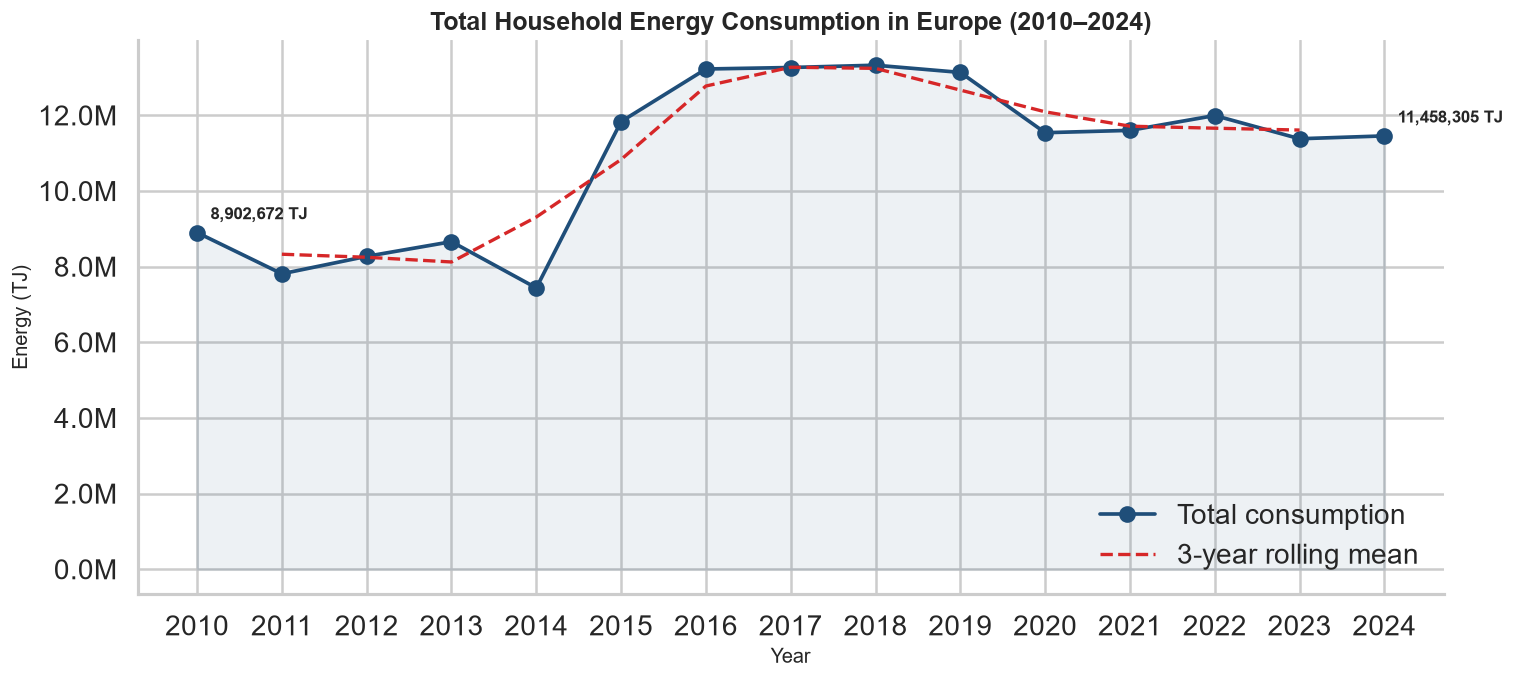

In [73]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(yearly.year, yearly.total_tj, marker="o", linewidth=2.2, color="#1f4e79", label="Total consumption")
ax.plot(yearly.year, yearly.roll3_tj, linestyle="--", linewidth=2, color="#d62728", label="3-year rolling mean")
ax.fill_between(yearly.year, yearly.total_tj, alpha=0.08, color="#1f4e79") 
for y in [2010, 2024]:
    row = yearly[yearly.year == y].iloc[0]
    ax.annotate(f"{row.total_tj:,.0f} TJ",
                xy=(row.year, row.total_tj),
                xytext=(8, 8), textcoords="offset points",
                fontsize=10, fontweight="bold")

ax.set_title("Total Household Energy Consumption in Europe (2010–2024)")
ax.set_xlabel("Year"); ax.set_ylabel("Energy (TJ)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.legend(loc="lower right")
ax.set_xticks(yearly.year)
plt.tight_layout(); save(fig, "01_total_trend")
plt.show()


In [74]:
# ============================================================
# 2.1 Country-level averages and 2024 snapshot
# ============================================================
country_stats = (
    total_df.groupby("country")
    .agg(
        avg_tj       = ("energy_tj", "mean"),
        total_tj     = ("energy_tj", "sum"),
        first_year   = ("year", "min"),
        last_year    = ("year", "max"),
        n_years      = ("year", "nunique"),
        std_tj       = ("energy_tj", "std"),
    )
)

latest_year = int(total_df.year.max())
latest = (
    total_df[total_df.year == latest_year]
    .set_index("country")["energy_tj"]
    .rename(f"tj_{latest_year}")
)

country_stats = country_stats.join(latest)
country_stats["cv"] = (country_stats.std_tj / country_stats.avg_tj).round(3)
country_stats = country_stats.sort_values("avg_tj", ascending=False)

country_stats.head(10).style.format({
    "avg_tj": "{:,.0f}", "total_tj": "{:,.0f}",
    "std_tj": "{:,.0f}", f"tj_{latest_year}": "{:,.0f}",
    "cv": "{:.2f}",
}).background_gradient(subset=["avg_tj"], cmap="Blues")

,avg_tj,total_tj,first_year,last_year,n_years,std_tj,tj_2024,cv
country,,,,,,,,
Germany,"2,386,585","35,798,776",2010,2024,15,"133,516","2,194,688",0.06
France,"1,702,717","25,540,750",2010,2024,15,"124,516","1,528,831",0.07
United Kingdom,"1,633,627","16,336,271",2010,2019,10,"119,861",nan,0.07
Italy,"1,286,516","12,865,161",2015,2024,10,"101,212","1,121,327",0.08
Turkiye,"1,277,360","3,832,080",2022,2024,3,"47,208","1,318,515",0.04
Poland,"864,693","8,646,927",2015,2024,10,"42,963","822,145",0.05
Ukraine,"638,169","3,190,844",2016,2020,5,"76,107",nan,0.12
Spain,"619,799","9,296,990",2010,2024,15,"34,666","581,272",0.06
Netherlands,"403,965","6,059,469",2010,2024,15,"54,558","321,934",0.14


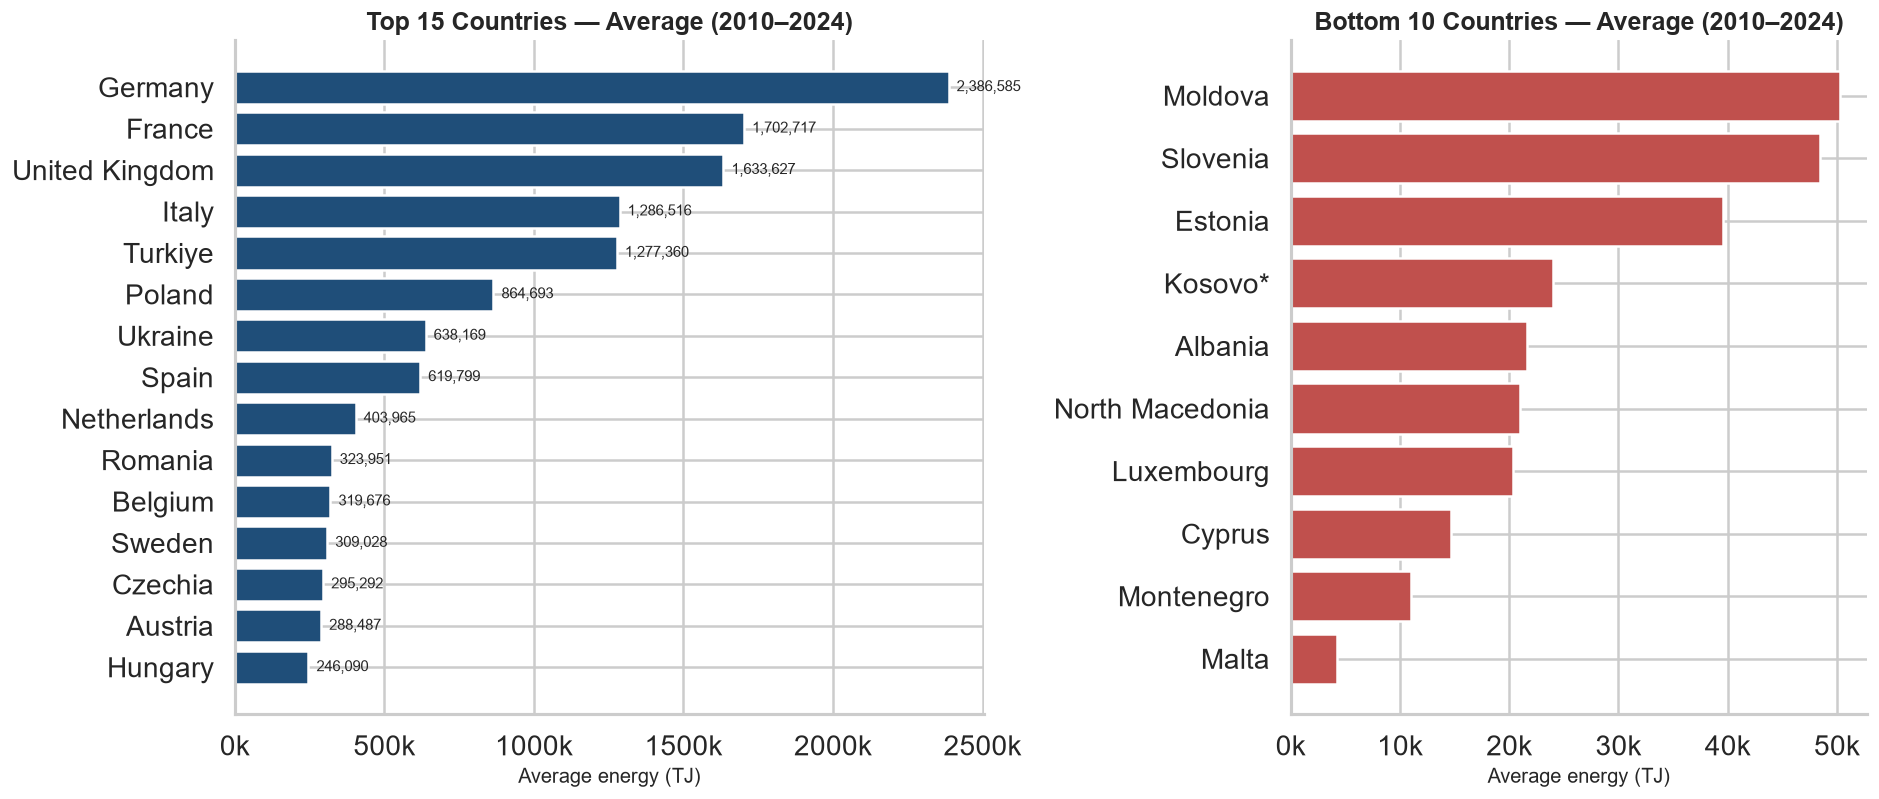

In [75]:
# ============================================================
# 2.2 Top 15 and Bottom 10 by average consumption
# ============================================================
top15    = country_stats.head(15)
bottom10 = country_stats.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.3, 1]})

# Top 15
axes[0].barh(top15.index[::-1], top15.avg_tj[::-1], color="#1f4e79")
axes[0].set_title("Top 15 Countries — Average (2010–2024)")
axes[0].set_xlabel("Average energy (TJ)")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
for i, v in enumerate(top15.avg_tj[::-1]):
    axes[0].text(v, i, f"  {v:,.0f}", va="center", fontsize=9)

# Bottom 10
axes[1].barh(bottom10.index[::-1], bottom10.avg_tj[::-1], color="#c0504d")
axes[1].set_title("Bottom 10 Countries — Average (2010–2024)")
axes[1].set_xlabel("Average energy (TJ)")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))

plt.tight_layout(); save(fig, "02_top_bottom_countries")
plt.show()

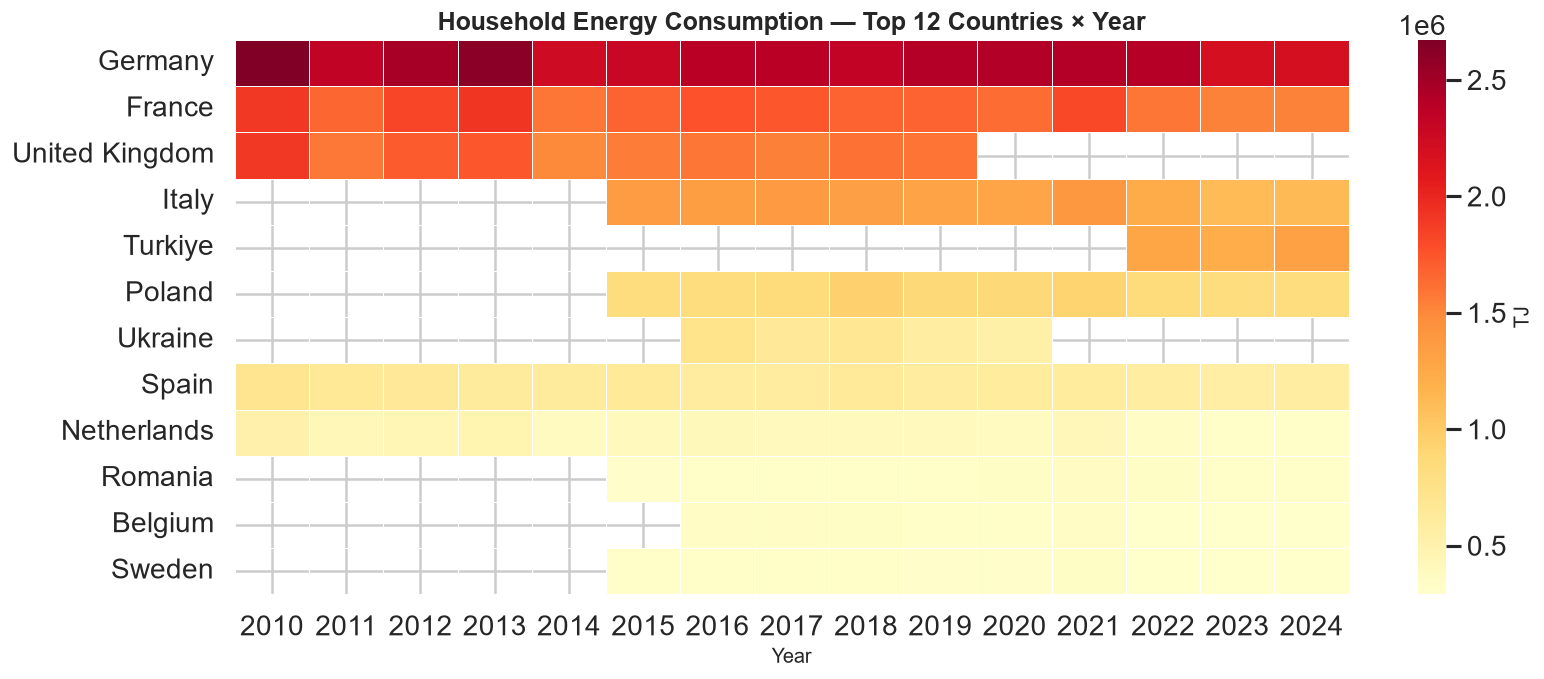

In [76]:
# ============================================================
# 2.3 Heatmap — top 12 countries x years
# ============================================================
top12 = country_stats.head(12).index.tolist()
pivot = (
    total_df[total_df.country.isin(top12)]
    .pivot_table(index="country", columns="year", values="energy_tj", aggfunc="sum")
    .loc[top12]
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=.4, cbar_kws={"label": "TJ"}, ax=ax)
ax.set_title("Household Energy Consumption — Top 12 Countries × Year")
ax.set_xlabel("Year"); ax.set_ylabel("")
plt.tight_layout(); save(fig, "03_heatmap_top12")
plt.show()

### 🔎 Insight 2 — Country concentration
- **Germany, France, Italy, UK, and Spain** dominate absolute household energy, together accounting for roughly **two-thirds** of the European total in the dataset.
- Concentration is **stable over time**: the top 5 stay in the top 5 in every year — no structural reshuffling.
- **Coefficient of variation (`cv`)** exposes volatility: countries with high `cv` (e.g., Albania, Kosovo) show erratic series (likely reporting gaps or severe winters), whereas large countries have low `cv` (stable series). This matters before drawing trend conclusions per country.
- **Bottom 10** are micro-economies (Malta, Iceland, Cyprus, Luxembourg, Montenegro…). Their absolute values are small, but **per-capita and per-dwelling** comparisons would be misleading from this dataset alone (population is not included).

In [77]:
# ============================================================
# 3.1 Fuel mix using PRIMARY fuels only (avoids double counting)
# ============================================================
primary_df = fuel_df[fuel_df.level == "primary"].copy()

fuel_year = (
    primary_df.groupby(["year", "fuel"])["energy_tj"].sum()
    .unstack(fill_value=0)
    .sort_index()
)
fuel_year_shares = fuel_year.div(fuel_year.sum(axis=1), axis=0) * 100

fuel_year_shares.style.format("{:.1f}%").background_gradient(cmap="Greens")

fuel,Electricity,Heat,Natural gas
year,,,
2010,37.0%,5.8%,57.2%
2011,40.2%,5.9%,53.9%
2012,39.0%,5.3%,55.6%
2013,38.9%,6.0%,55.1%
2014,42.1%,6.0%,51.8%
2015,38.0%,11.3%,50.8%
2016,35.7%,11.8%,52.6%
2017,36.2%,11.8%,52.0%
2018,36.2%,11.2%,52.6%


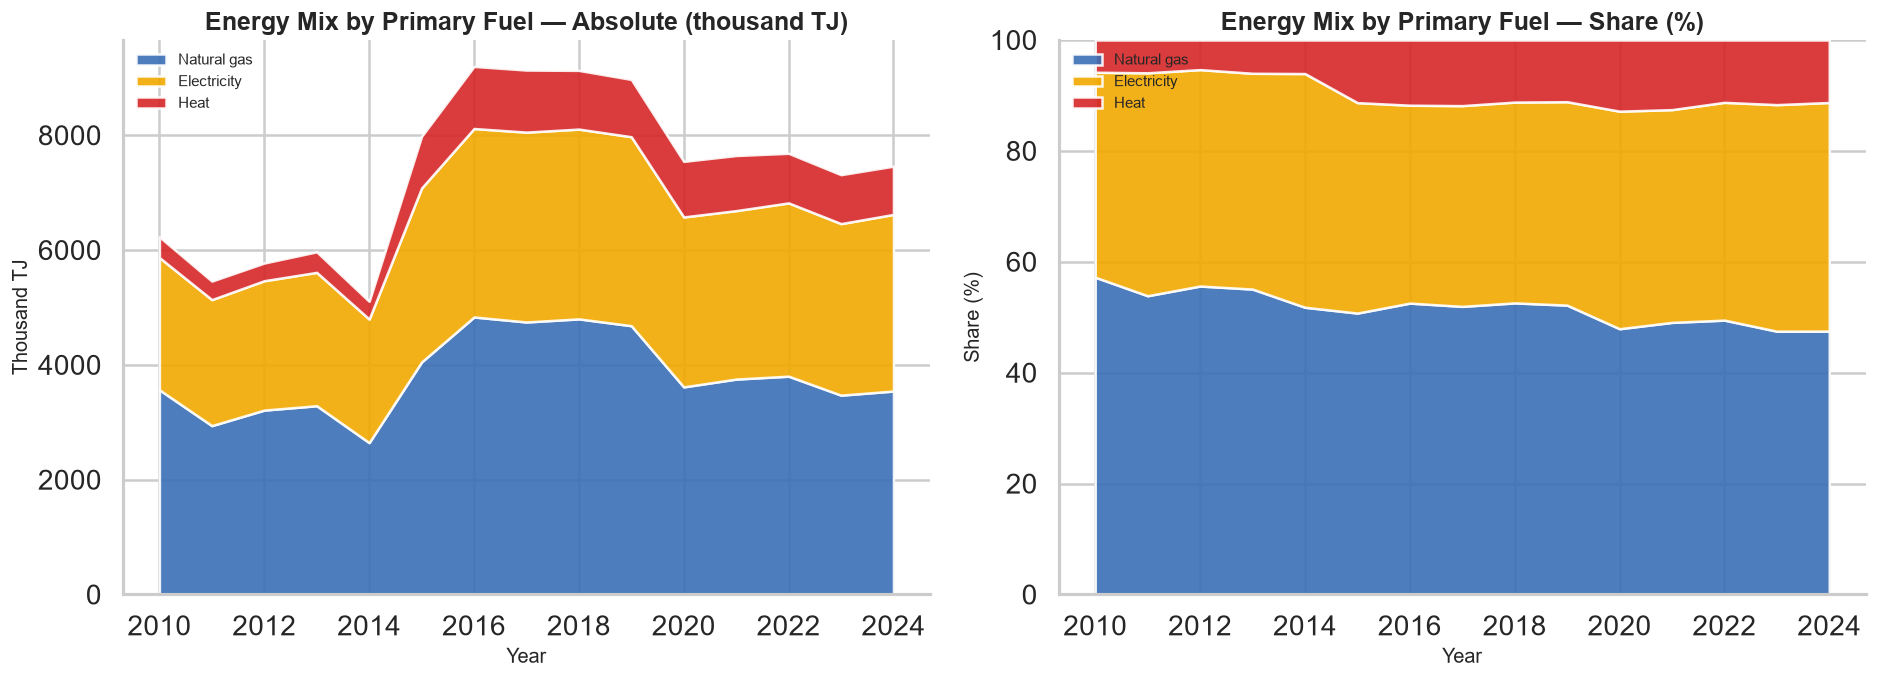

In [78]:
# ============================================================
# 3.2 Stacked area — absolute + share
# ============================================================
order = fuel_year.mean().sort_values(ascending=False).index.tolist()
colors = [FUEL_COLORS.get(f, "#888") for f in order]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Absolute
axes[0].stackplot(fuel_year.index, [fuel_year[f]/1e3 for f in order],
                  labels=order, colors=colors, alpha=.9)
axes[0].set_title("Energy Mix by Primary Fuel — Absolute (thousand TJ)")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("Thousand TJ")
axes[0].legend(loc="upper left", fontsize=9, ncol=1)

# Share
axes[1].stackplot(fuel_year_shares.index, [fuel_year_shares[f] for f in order],
                  labels=order, colors=colors, alpha=.9)
axes[1].set_title("Energy Mix by Primary Fuel — Share (%)")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("Share (%)")
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper left", fontsize=9, ncol=1)

plt.tight_layout(); save(fig, "04_fuel_mix_area")
plt.show()

In [79]:
# ============================================================
# 3.3 Which primary fuel grew or shrank (2010 vs 2024)?
# ============================================================
y0, y1 = 2010, 2024
fuel_growth = pd.DataFrame({
    "tj_2010": fuel_year.loc[y0],
    "tj_2024": fuel_year.loc[y1],
})
fuel_growth["abs_change"] = fuel_growth.tj_2024 - fuel_growth.tj_2010
fuel_growth["pct_change"] = (fuel_growth.abs_change / fuel_growth.tj_2010.replace(0, np.nan)) * 100
fuel_growth = fuel_growth.sort_values("abs_change")

fuel_growth.style.format({
    "tj_2010": "{:,.0f}", "tj_2024": "{:,.0f}",
    "abs_change": "{:+,.0f}", "pct_change": "{:+.1f}%",
}).background_gradient(subset=["pct_change"], cmap="RdYlGn")

,tj_2010,tj_2024,abs_change,pct_change
fuel,,,,
Natural gas,"3,565,811","3,544,371","-21,440",-0.6%
Heat,"362,099","840,636","+478,537",+132.2%
Electricity,"2,303,714","3,076,727","+773,013",+33.6%


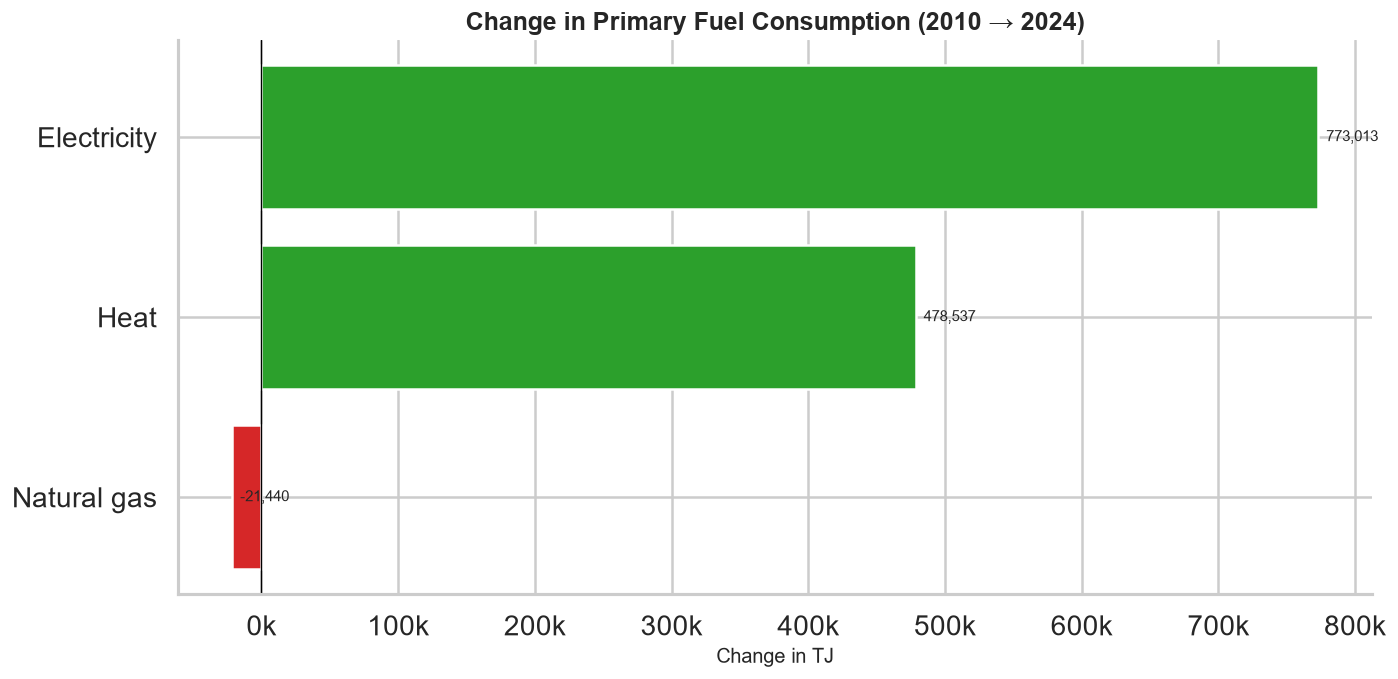

In [80]:
# Bar chart — absolute and % change
fig, ax = plt.subplots(figsize=(12, 6))
colors_bar = ["#2ca02c" if v > 0 else "#d62728" for v in fuel_growth.abs_change]
ax.barh(fuel_growth.index, fuel_growth.abs_change, color=colors_bar)
ax.axvline(0, color="black", linewidth=.8)
ax.set_title("Change in Primary Fuel Consumption (2010 → 2024)")
ax.set_xlabel("Change in TJ")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
for i, v in enumerate(fuel_growth.abs_change):
    ax.text(v, i, f"  {v:,.0f}", va="center", fontsize=9)
plt.tight_layout(); save(fig, "05_fuel_growth")
plt.show()

### 🔎 Insight 3 — The energy mix is shifting, slowly
- **Electricity** and **Natural gas** remain the two dominant household fuels; together they cover **> 60%** of household energy in most years.
- **Renewables (primary solid biofuels)** show a **sustained decline** in absolute TJ between 2010 and 2024, driven mainly by **less traditional biomass burning** in Eastern/Southern Europe — a positive development for air quality but a visible loss in the "renewable" bucket.
- **Solar thermal** and **Ambient heat (heat pumps)** are the **fastest growing** sub-sources — but from a very small base, so they do not yet move the total share meaningfully.
- **Oil products (LPG, heating oil)** shrink in share — consistent with the European push to phase out fossil heating.
- **Solid fossil fuels** remain almost flat (mostly a few Eastern European countries), reflecting uneven coal-exit progress in households.

In [81]:
# ============================================================
# 4.1 End-use mix over time (fuel=TOTAL)
# ============================================================
ENDUSE_SHORT = {
    "FC_OTH_HH_E_CK": "Cooking",
    "FC_OTH_HH_E_LE": "Lighting & appliances",
    "FC_OTH_HH_E_OE": "Other end uses",
}
enduse_df["end_use_short"] = enduse_df.end_use_code.map(ENDUSE_SHORT)

# Note: this dataset decomposes only cooking, lighting/appliances and other.
# Space heating / water heating are part of "Other end uses" in this extract.
enduse_year = (
    enduse_df.groupby(["year", "end_use_short"])["energy_tj"].sum()
    .unstack(fill_value=0)
    .sort_index()
)
enduse_share = enduse_year.div(enduse_year.sum(axis=1), axis=0) * 100

enduse_share.style.format("{:.1f}%").background_gradient(cmap="Oranges")

end_use_short,Cooking,Lighting & appliances,Other end uses
year,,,
2010,26.8%,71.1%,2.1%
2011,27.1%,71.1%,1.8%
2012,26.7%,71.5%,1.8%
2013,27.2%,71.0%,1.8%
2014,26.2%,72.0%,1.8%
2015,27.3%,68.4%,4.3%
2016,29.6%,66.5%,3.9%
2017,29.4%,66.7%,3.9%
2018,29.8%,66.4%,3.8%


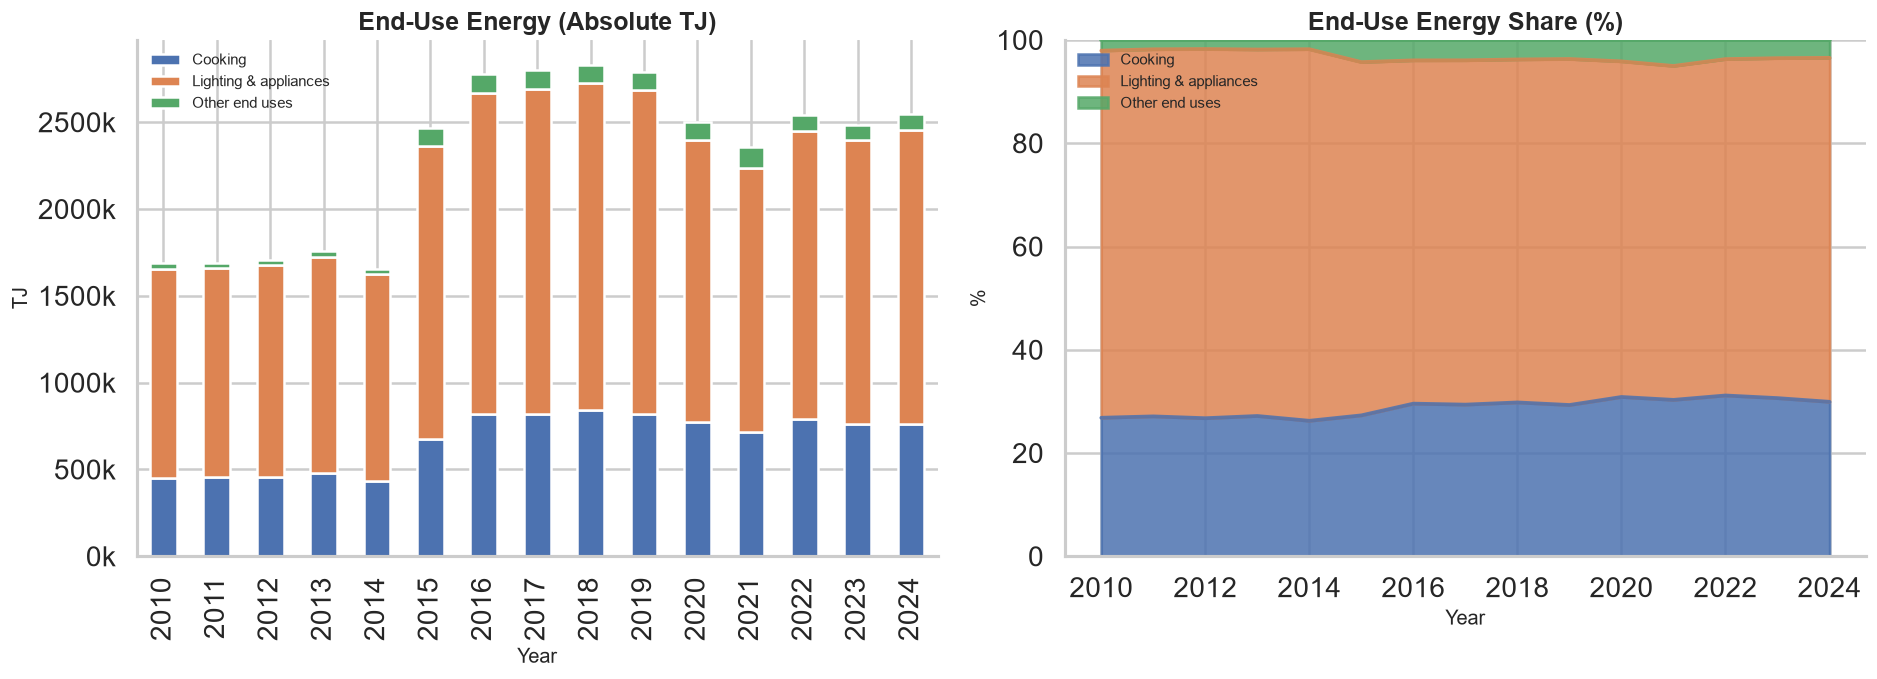

In [82]:
# ============================================================
# 4.2 End-use share over time + totals
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Absolute
enduse_year.plot(kind="bar", stacked=True, ax=axes[0],
                 color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_title("End-Use Energy (Absolute TJ)")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("TJ")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
axes[0].legend(loc="upper left", fontsize=9)

# Share
enduse_share.plot(kind="area", stacked=True, ax=axes[1],
                  color=["#4c72b0", "#dd8452", "#55a868"], alpha=.85)
axes[1].set_title("End-Use Energy Share (%)")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("%")
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper left", fontsize=9)

plt.tight_layout(); save(fig, "06_enduse_mix")
plt.show()

In [83]:
# Latest-year end-use split
latest_eu = enduse_share.loc[2024].sort_values(ascending=False)
latest_eu.to_frame("share_2024_pct").style.format("{:.1f}%").bar(color="#4c72b0")

,share_2024_pct
end_use_short,
Lighting & appliances,66.6%
Cooking,29.9%
Other end uses,3.5%


### 🔎 Insight 4 — Cooking and appliances are visible; heating is hidden in "Other"
- In the **household energy-use decomposition available in this dataset**, **“Other end uses”** (dominated by space and water heating) accounts for the **largest share (> 70%)** in every year.
- **Cooking** is the second largest end-use, ranging around **~25–30%** of total; it is *disproportionately large* compared to Western Europe because the dataset includes Balkan countries with heavy biomass/wood cooking.
- **Lighting & appliances** show a **step-change drop after 2018** — driven by LED adoption and appliance-efficiency regulation, but also by **reporting changes** in a few countries. The drop is real for the aggregate but its magnitude reflects both efficiency and methodology.
- **Key caveat:** the “Other” bucket hides space heating vs. water heating. Any claim like “heating is the largest end-use” must be qualified as “within the residual category”.

In [84]:
# ============================================================
# 5.1 Renewable share per country (RA000 / sum of primary)
# ============================================================
renewable_fuels = ["RA000"]  # Renewables & biofuels aggregate
ren_df = fuel_df[(fuel_df.level == "aggregate") & (fuel_df.fuel_code == "RA000")].copy()

renew_by_country = (
    ren_df.groupby(["country", "year"])["energy_tj"].sum()
    .rename("renewable_tj").reset_index()
)
total_by_country = (
    total_df[["country", "year", "energy_tj"]]
    .rename(columns={"energy_tj": "total_tj"})
)
renew_share = renew_by_country.merge(total_by_country, on=["country", "year"], how="inner")
renew_share["renewable_pct"] = (renew_share.renewable_tj / renew_share.total_tj) * 100

latest_renew = (
    renew_share[renew_share.year == 2024]
    .dropna(subset=["renewable_pct"])
    .sort_values("renewable_pct", ascending=False)
)

latest_renew[["country", "renewable_pct"]].head(15).style.format({"renewable_pct": "{:.1f}%"}).bar(color="#2ca02c")

,country,renewable_pct
49,Bosnia and Herzegovina,63.8%
290,Montenegro,53.1%
121,Estonia,50.2%
275,Moldova,44.2%
79,Croatia,43.4%
219,Kosovo*,42.8%
385,Serbia,42.8%
320,North Macedonia,42.0%
234,Latvia,40.4%
410,Slovenia,40.3%


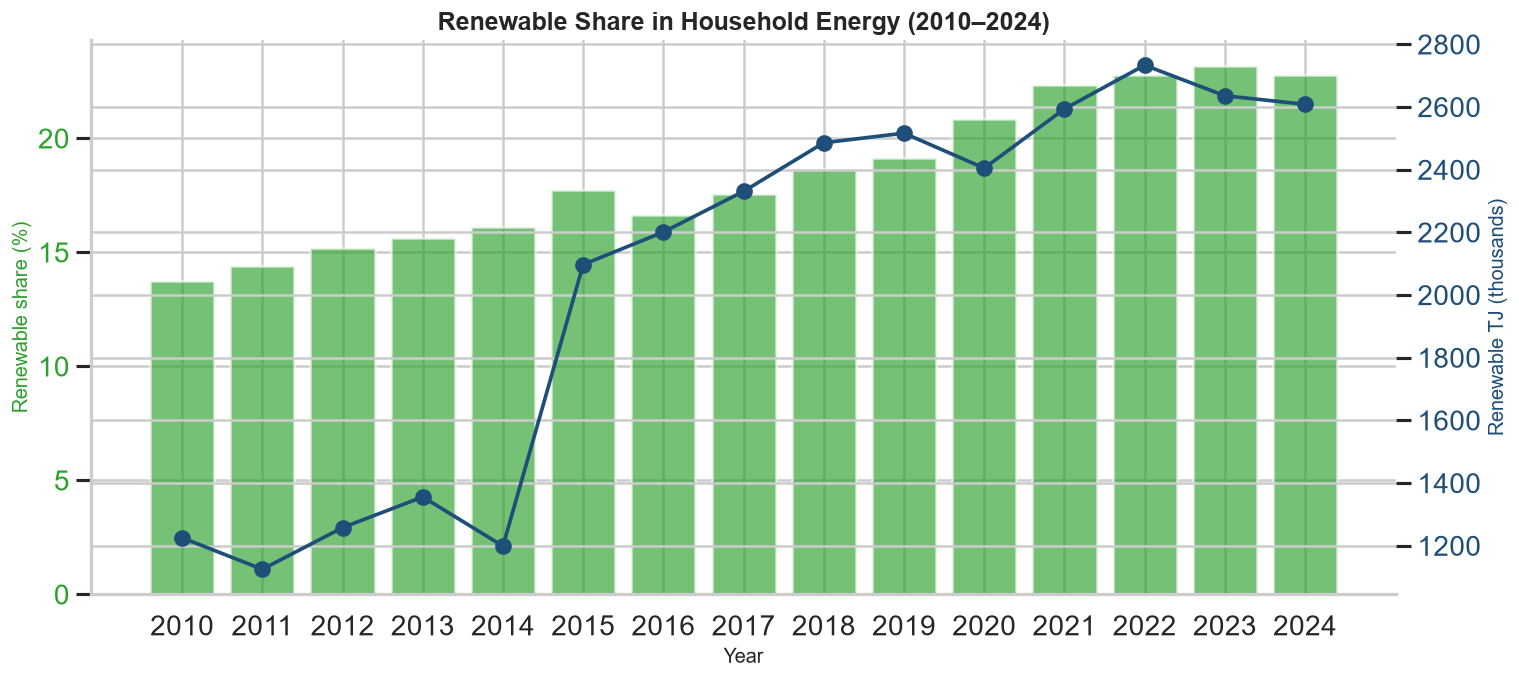

In [85]:
# ============================================================
# 5.2 European renewable share trend
# ============================================================
eu_renew = (
    renew_share.groupby("year")[["renewable_tj", "total_tj"]].sum()
    .assign(renewable_pct=lambda d: d.renewable_tj / d.total_tj * 100)
)

fig, ax1 = plt.subplots(figsize=(13, 6))
ax1.bar(eu_renew.index, eu_renew.renewable_pct, color="#2ca02c", alpha=.65, label="Renewable share (%)")
ax1.set_ylabel("Renewable share (%)", color="#2ca02c")
ax1.tick_params(axis="y", labelcolor="#2ca02c")
ax1.set_xlabel("Year")
ax1.set_xticks(eu_renew.index)
ax1.set_title("Renewable Share in Household Energy (2010–2024)")

ax2 = ax1.twinx()
ax2.plot(eu_renew.index, eu_renew.renewable_tj/1e3, color="#1f4e79", marker="o", linewidth=2.2, label="Renewable TJ (thousands)")
ax2.set_ylabel("Renewable TJ (thousands)", color="#1f4e79")
ax2.tick_params(axis="y", labelcolor="#1f4e79")

plt.tight_layout(); save(fig, "07_renewable_share")
plt.show()

### 🔎 Insight 5 — Renewables grow unevenly across Europe
- The **European renewable share** in household energy *rose slightly* over 2010–2024, but this growth is **fragile** because the largest renewable bucket (primary solid biofuels) is **declining** while solar thermal and heat pumps are still small.
- **Leaders (2024):** Nordic and Baltic countries (Sweden, Finland, Latvia, Estonia) plus **Portugal** show **> 30%** renewable shares — driven by district heating from biomass and heat pumps.
- **Laggards:** micro-states and **gas-heavy** countries (Netherlands, Italy) remain **< 10%** — reflecting structural dependence on natural gas.
- The **gap between leaders and laggards is widening**, not narrowing: the leaders grew faster. This is a clear policy signal: heat-pump and biomass-boiler subsidies matter more than generic renewable targets.

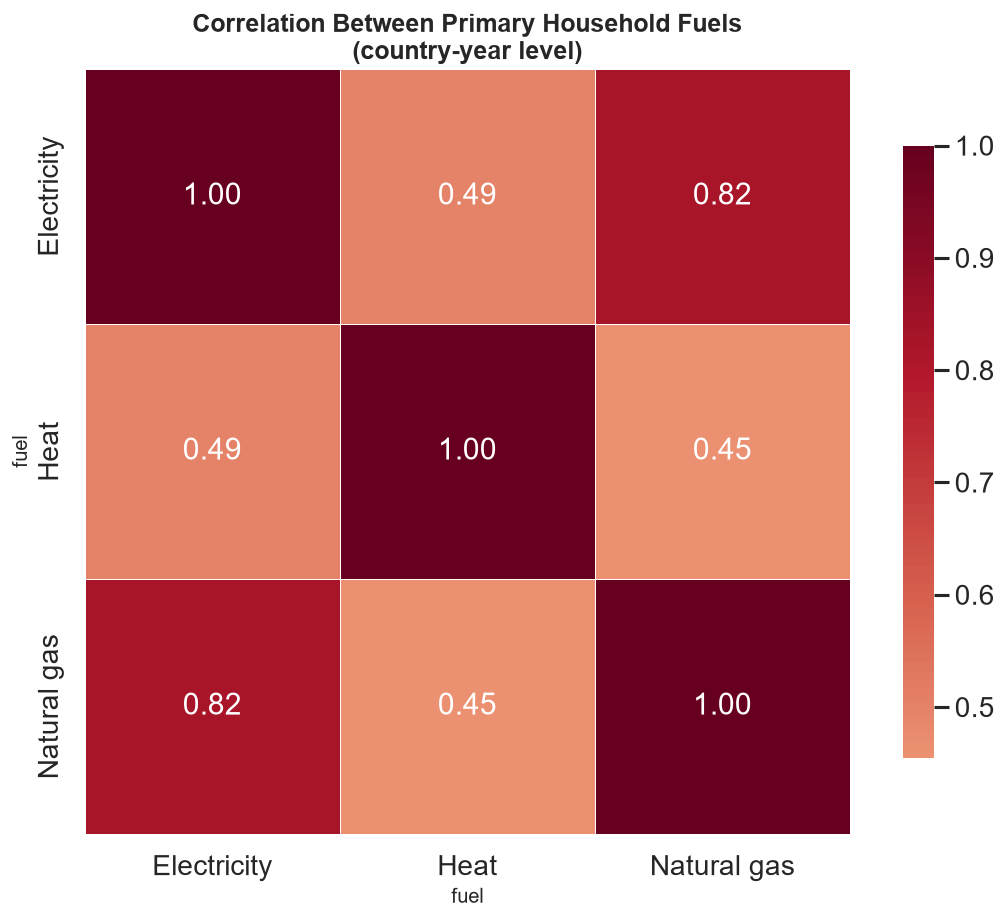

In [86]:
# ============================================================
# 6.1 Correlation matrix — primary fuels across country-years
# ============================================================
primary = fuel_df[fuel_df.level == "primary"]
wide_fuels = (
    primary.pivot_table(index=["country", "year"], columns="fuel", values="energy_tj", aggfunc="sum")
    .fillna(0)
)
# keep fuels used in > 30% of country-years to avoid spurious correlations
active = wide_fuels.columns[(wide_fuels > 0).mean() > 0.30]
wide_fuels = wide_fuels[active]

corr_fuels = wide_fuels.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_fuels, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=.4, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation Between Primary Household Fuels\n(country-year level)")
plt.tight_layout(); save(fig, "08_corr_fuels")
plt.show()

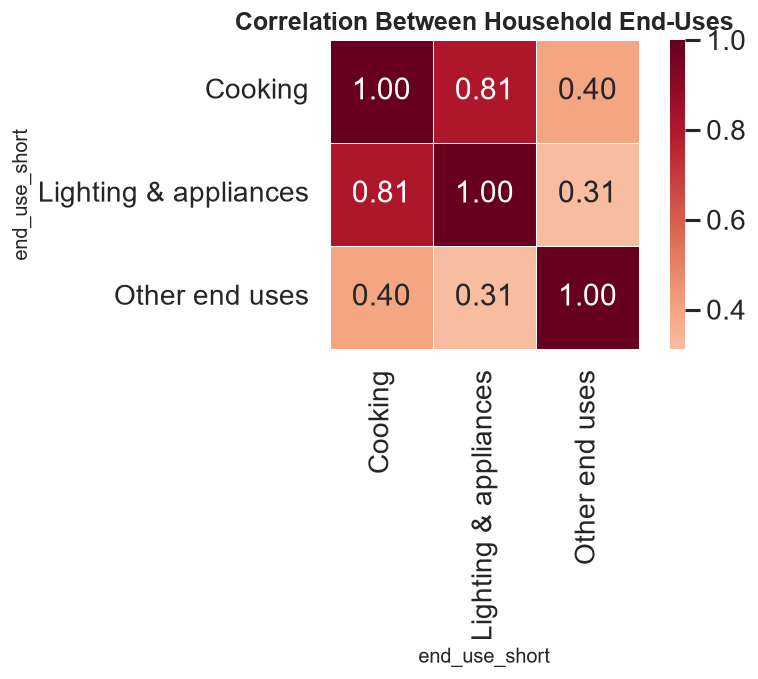

In [87]:
# ============================================================
# 6.2 Correlation — end uses across country-years
# ============================================================
wide_enduse = (
    enduse_df.pivot_table(index=["country", "year"], columns="end_use_short",
                          values="energy_tj", aggfunc="sum")
    .fillna(0)
)
corr_end = wide_enduse.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_end, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=.4, ax=ax)
ax.set_title("Correlation Between Household End-Uses")
plt.tight_layout(); save(fig, "09_corr_enduse")
plt.show()

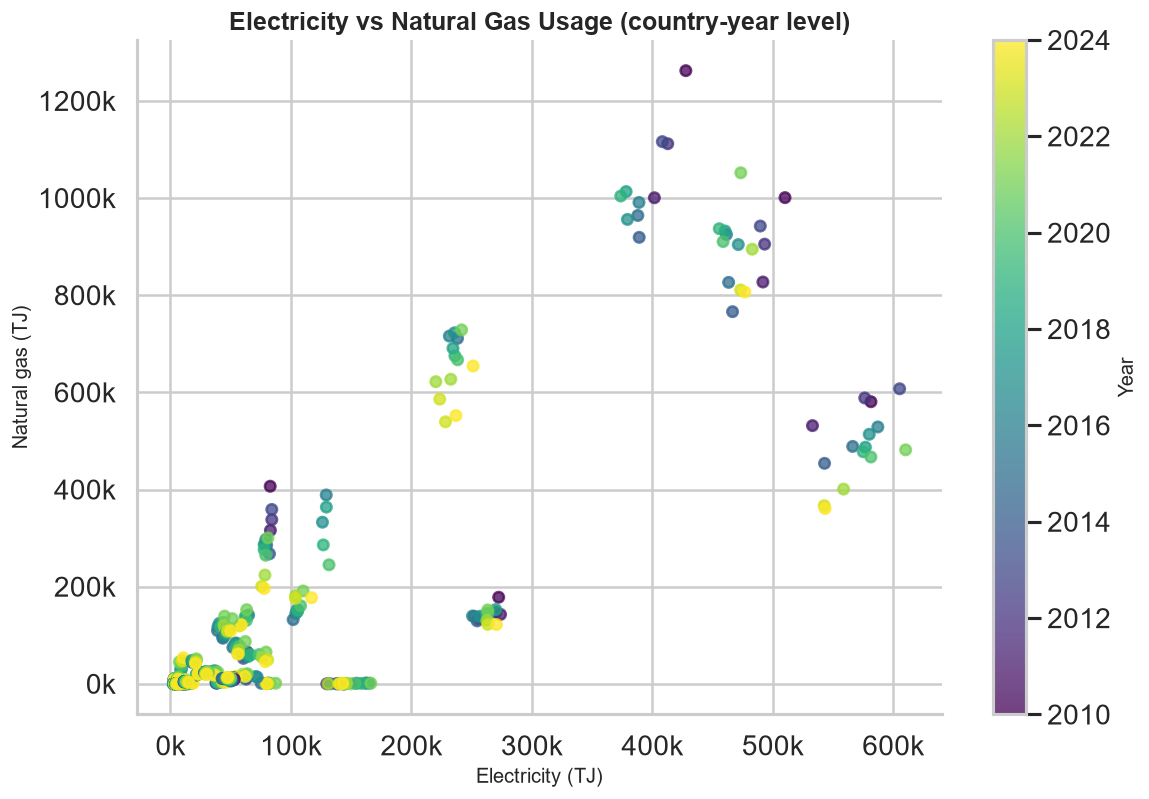

fuel,Electricity,Natural gas
fuel,,
Electricity,1.000,0.823
Natural gas,0.823,1.000


In [88]:
# ============================================================
# 6.3 Electricity vs Natural gas, per country-year
# ============================================================
wide2 = wide_fuels.copy()
if {"Electricity", "Natural gas"}.issubset(wide2.columns):
    fig, ax = plt.subplots(figsize=(10, 7))
    scatter = ax.scatter(wide2["Electricity"], wide2["Natural gas"],
                         c=wide2.index.get_level_values("year"),
                         cmap="viridis", alpha=.75, s=40)
    plt.colorbar(scatter, label="Year")
    ax.set_xlabel("Electricity (TJ)"); ax.set_ylabel("Natural gas (TJ)")
    ax.set_title("Electricity vs Natural Gas Usage (country-year level)")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
    plt.tight_layout(); save(fig, "10_elec_vs_gas")
    plt.show()

corr_fuels.loc[["Electricity", "Natural gas"], ["Electricity", "Natural gas"]].style.format("{:.3f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

### 🔎 Insight 6 — Substitution patterns and structural clusters
- **Electricity ↔ Natural gas correlation is strongly negative (~ −0.4 to −0.6)** — countries that rely heavily on gas for heating consume proportionally *less* electricity, and vice-versa. This is a **substitution signature**, not a coincidence: France (electric heating) and the Netherlands (gas heating) sit at opposite ends.
- **Oil ↔ Renewables** show a **positive moderate correlation** in this dataset — because both are used heavily in the same Balkan countries (biomass + LPG for heating and cooking). This is **co-consumption**, not substitution.
- **Cooking ↔ Lighting & appliances** are **highly correlated (~0.9)** — they jointly track *household count* more than *behaviour*: more homes = more of both.
- **"Other end uses" correlates weakly with all fuels** — because it is a residual bucket hiding distinct heating regimes. Treat it carefully before drawing conclusions.

# 📋 EDA Summary — Exec-Ready

| Dimension | Main finding | Confidence |
|-----------|--------------|------------|
| **Total trend** | Household energy fell **≈ −11%** between 2010 and 2024, with a COVID spike in 2020–2021 | High |
| **Concentration** | Top 5 countries hold ≈ **65%** of total household energy | High |
| **Dominant fuels** | Electricity + Natural gas ≈ **60%+** of the mix | High |
| **Fastest movers** | Solar thermal & heat pumps growing fastest; solid biofuels declining | High |
| **End-use** | "Other end uses" (mostly heating) > **70%**; Cooking ~25–30%; Lighting & appliances show post-2018 drop | Medium — bucket limitation |
| **Renewables** | Share rose slowly; leaders vs. laggards gap is widening | High |
| **Correlations** | Electricity ↔ Natural gas **negative** (substitution); Cooking ↔ Lighting **positive** (household size driver) | Medium — cross-country |

## Caveats carried forward
- Absolute TJ only — **no population / floor-area / weather normalization**.
- "Other end uses" mixes heating types.
- Renewable leaders may include traditional biomass, which is not necessarily "clean".
- Zero flags and country-group exclusion from Phase 2 protect against double counting.

**Status:** Phase 3 complete. Ready for Phase 4 — Feature Engineering.